--- 1. Data Inspection ---
<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   OrderID        505 non-null    int64  
 1   OrderDate      505 non-null    str    
 2   Category       505 non-null    str    
 3   Region         505 non-null    str    
 4   PaymentMethod  499 non-null    str    
 5   Price          505 non-null    int64  
 6   Quantity       505 non-null    int64  
 7   CustomerAge    494 non-null    float64
 8   Revenue        505 non-null    int64  
dtypes: float64(1), int64(4), str(4)
memory usage: 35.6 KB
None

--- 2. Identifying Missing Values & Duplicates ---
Duplicates before cleaning: 5
Missing values before cleaning:
 OrderID           0
OrderDate         0
Category          0
Region            0
PaymentMethod     6
Price             0
Quantity          0
CustomerAge      11
Revenue           0
dtype: int64

--- 3. Data Cleaning --

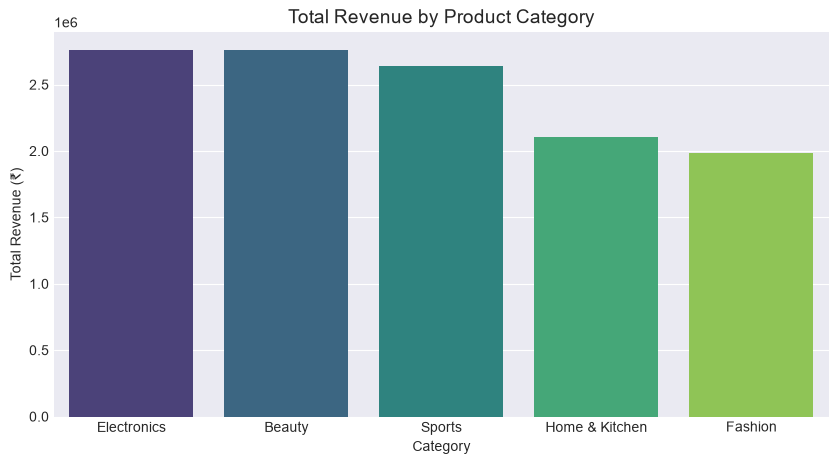

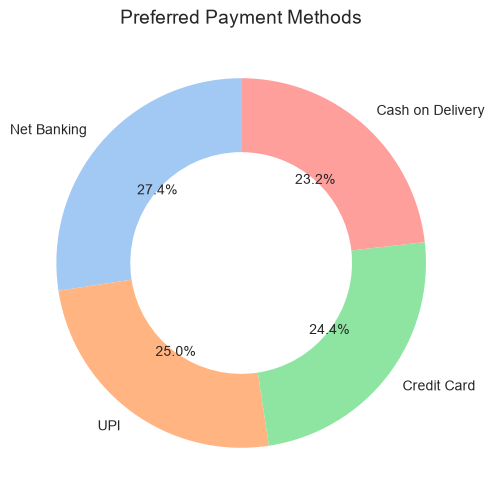

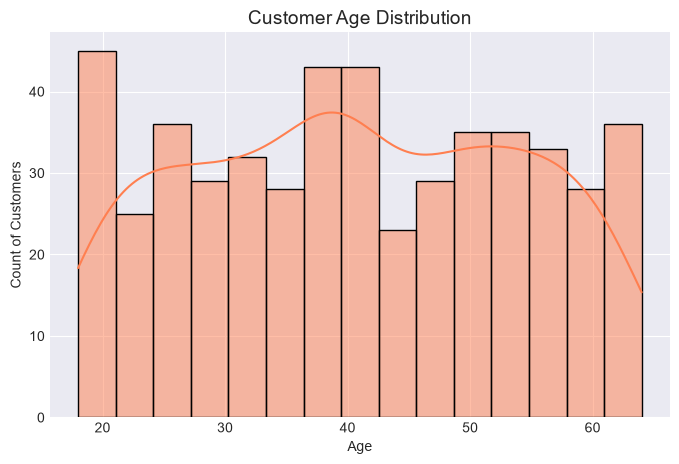

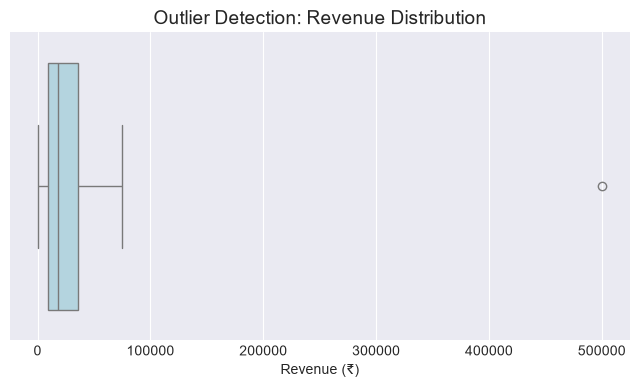

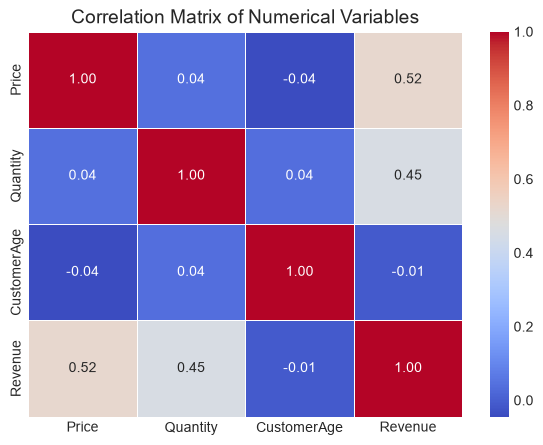


Cleaned data saved as 'cleaned_retail_sales_data.csv' for Power BI!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# TASK 3: Dataset Selection & Data Preparation
# ==========================================
print("--- 1. Data Inspection ---")
df = pd.read_csv('retail_sales_data.csv')
print(df.info())

print("\n--- 2. Identifying Missing Values & Duplicates ---")
print(f"Duplicates before cleaning: {df.duplicated().sum()}")
print("Missing values before cleaning:\n", df.isnull().sum())

print("\n--- 3. Data Cleaning ---")
# Handling Missing Values
df['CustomerAge'] = df['CustomerAge'].fillna(df['CustomerAge'].median())
df['PaymentMethod'] = df['PaymentMethod'].fillna(df['PaymentMethod'].mode()[0])

# Removing Duplicates
df = df.drop_duplicates()
print(f"Duplicates after cleaning: {df.duplicated().sum()}")
print("Missing values after cleaning: None!")

# ==========================================
# TASK 4: Exploratory Data Analysis (EDA)
# ==========================================
print("\n--- 4. Descriptive Statistics ---")
print(df.describe())

# ==========================================
# TASK 5: Data Visualization (5 Charts)
# ==========================================
plt.style.use('seaborn-v0_8-darkgrid')

# Chart 1: Bar Chart - Revenue by Category
plt.figure(figsize=(10, 5))
category_revenue = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
sns.barplot(x=category_revenue.index, y=category_revenue.values, palette='viridis')
plt.title('Total Revenue by Product Category', fontsize=14)
plt.xlabel('Category')
plt.ylabel('Total Revenue (₹)')
plt.show()

# Chart 2: Donut Chart - Payment Methods
plt.figure(figsize=(6, 6))
payment_counts = df['PaymentMethod'].value_counts()
plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%', startangle=90, 
        colors=sns.color_palette('pastel'), wedgeprops={'width': 0.4})
plt.title('Preferred Payment Methods', fontsize=14)
plt.show()

# Chart 3: Histogram - Customer Age Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['CustomerAge'], bins=15, kde=True, color='coral')
plt.title('Customer Age Distribution', fontsize=14)
plt.xlabel('Age')
plt.ylabel('Count of Customers')
plt.show()

# Chart 4: Boxplot - Identifying Outliers in Revenue
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Revenue'], color='lightblue')
plt.title('Outlier Detection: Revenue Distribution', fontsize=14)
plt.xlabel('Revenue (₹)')
plt.show()

# Chart 5: Correlation Heatmap
plt.figure(figsize=(7, 5))
corr_matrix = df[['Price', 'Quantity', 'CustomerAge', 'Revenue']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Numerical Variables', fontsize=14)
plt.show()

# Saving the cleaned dataset for Power BI
df.to_csv('cleaned_retail_sales_data.csv', index=False)
print("\nCleaned data saved as 'cleaned_retail_sales_data.csv' for Power BI!")